# AgroSmart Puno · MIJAEL · DimensiónU2 — Temperatura exterior (Azángaro) en tiempo real (S6 → S12)
**Estudiante:** Mijael Yurins Coaquira Justo · **Equipo:** Jose Armando Mamani Poccohuanca y Mijael Yurins Coaquira Justo

**Pregunta central del proyecto:** ¿cómo anticipar a corto plazo las condiciones meteorológicas de riesgo agrícola del altiplano de Puno (estrés hídrico del suelo y heladas) a partir de datos de Open-Meteo?
**Dimensión de Mijael:** *«¿Qué temperatura exterior se espera en la zona de referencia de Azángaro una hora después, a partir de los datos meteorológicos de Open-Meteo?»*
**DimensiónU2 (indicador streaming):** temperatura **en vivo**, dato por dato, y su **predicción a +1 h** actualizándose junto con ella en el Grafana común, con **alerta de helada**.

```
Open-Meteo (temperature_2m, Azángaro) ─► producer_api_temperatura ─► Kafka …-temperatura-telemetria ─┬─► Spark Structured Streaming (consumer persistente)
 Carga inicial simulada (90 d) ─────────► PostgreSQL directo                                           │     eventos · ventanas 1 h · watermark 2 h · dedup · inferencia +1 h
                                          producer_evaluaciones_temperatura ◄──────────────────────────┘                  │
                                          └► Kafka …-temperatura-empresarial (riesgo de helada simulado) ─► PostgreSQL ─► Grafana común + Prometheus
```
**Datos:** carga inicial **simulada** (90 días) + histórico API (≈60 días, real modelado) + API en tiempo real. La **prueba del modelo es el último 15 %: datos reales de la API**.

> ⚠️ Open-Meteo es *modelado*, no un termómetro; la carga inicial es *simulada*; el umbral de helada (0 °C) es *didáctico* y no es una alerta oficial (SENAMHI).

| Orden | Sesión | Qué se hace | Dónde |
|---|---|---|---|
| 0 | — | Entorno y servicios | este cuaderno |
| 1 | **S06** | Eventos empresariales en Kafka | CMD + este cuaderno |
| 2 | **S07** | Ingesta IoT/API, registros descargados y carga inicial | este cuaderno + CMD |
| 3 | **S08** | Spark Structured Streaming: consumer, **monitor en tiempo real**, SQL, watermark y checkpoints | CMD + este cuaderno |
| 4 | **S09** | Observabilidad (Prometheus/Grafana) y costos en S/ | CMD + este cuaderno |
| 5 | **S10** | Series de tiempo: entrenar +1 h e inferencia | este cuaderno |
| 6 | **S11** | BI/ML en Grafana | Grafana + este cuaderno |
| 7 | **S12** | Evidencias y ficha U2 | este cuaderno |

> La **primera vez** que se monta el proyecto, ejecuta la sección **10.1** (entrenar) antes de arrancar el consumer de la S08; después, el cuaderno se recorre en orden S06 → S11.

---
# 0 · Entorno y servicios
Ya debes tener Kafka y PostgreSQL+Jupyter arriba (ver `GUIA_EJECUCION_CMD.md`). El consumer de temperatura corre en **otro contenedor**.

In [1]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
import os, sys, json, math, time, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import psycopg2
from psycopg2.extras import execute_values
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, DecisionTreeRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

RAIZ = Path('/home/jovyan/work/Sensortemperatura')       # carpeta de trabajo de Mijael
REPO = Path('/home/jovyan/agrosmart-repo')
for p in ('datos', 'datos/bronze', 'modelos', 'resultados', 'evidencias', 'checkpoints'): (RAIZ/p).mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO/'uso-agrosmart'/'producer'))
KAFKA = os.getenv('KAFKA_BOOTSTRAP', 'kafka:9092')
TOP_TEL, TOP_EMP = 'agrosmart-u2-temperatura-telemetria', 'agrosmart-u2-temperatura-empresarial'
LAT, LON, UBIC, UMBRAL_HELADA = -14.91, -70.19, 'Azángaro', 0.0
PARAM_DB = dict(host=os.getenv('POSTGRES_HOST', 'postgres'), dbname=os.getenv('POSTGRES_DB', 'agrosmart_u2'),
                user=os.getenv('POSTGRES_USER', 'agrosmart'), password=os.getenv('POSTGRES_PASSWORD', ''), connect_timeout=10)

def sql(q, params=None, columnas=True):
    with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
        cur.execute(q, params)
        if cur.description is None: return None
        filas = cur.fetchall()
        return pd.DataFrame(filas, columns=[d[0] for d in cur.description]) if columnas else filas

with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:       # tablas (idempotente)
    cur.execute((REPO/'pyspark'/'sql'/'schema.sql').read_text(encoding='utf-8'))
    cur.execute((REPO/'pyspark'/'sql'/'schema_temperatura.sql').read_text(encoding='utf-8'))
print('Tablas de temperatura:', sql("SELECT table_name FROM information_schema.tables WHERE table_schema='public' AND table_name LIKE '%temperatura%' ORDER BY 1").table_name.tolist())
spark = (SparkSession.builder.master('local[2]').appName('AgroSmart-U2-Temperatura-ML')
         .config('spark.sql.shuffle.partitions', '2').config('spark.sql.session.timeZone', 'UTC').getOrCreate())
spark.sparkContext.setLogLevel('WARN'); print('Spark', spark.version, '| UTC', datetime.now(timezone.utc).isoformat())
from kafka import KafkaAdminClient
try:
    adm = KafkaAdminClient(bootstrap_servers=KAFKA, request_timeout_ms=8000); print('Kafka OK:', sorted(adm.list_topics())); adm.close()
except Exception as e:
    print('⚠️ Kafka no responde:', e)

Tablas de temperatura: ['comparacion_modelos_temperatura', 'eventos_empresariales_temperatura', 'eventos_temperatura', 'metricas_modelo_temperatura', 'predicciones_temperatura', 'ventanas_temperatura']
Spark 3.5.0 | UTC 2026-11-20T17:22:49.837904+00:00
Kafka OK: ['__consumer_offsets', 'agrosmart-u2-humedad-empresarial', 'agrosmart-u2-humedad-telemetria', 'agrosmart-u2-temperatura-empresarial', 'agrosmart-u2-temperatura-telemetria']


---
# SESIÓN 06 · Eventos empresariales en tiempo real (Kafka)
De cada lectura de temperatura nace una **evaluación simulada de riesgo de helada**: `alerta_helada` (≤ 0 °C), `vigilancia` (0–3 °C) o `normal`. No son ventas, ni daños, ni una alerta oficial.
## 6.1 Contrato de datos y regla de negocio (probada sin Kafka)

In [2]:
from decisiones_temperatura import crear_evaluacion
base_ev = {'evento_id': 'abc', 'fecha_evento': '2026-11-13T11:00:00Z', 'ubicacion': UBIC}
for t in (-2.5, 1.5, 9.0): print(f'{t:5.1f} °C →', crear_evaluacion({**base_ev, 'temperatura_c': t}, UMBRAL_HELADA)['estado'])
print(json.dumps(crear_evaluacion({**base_ev, 'temperatura_c': -2.5}), indent=2, ensure_ascii=False))
for nombre in ('telemetria_temperatura.json', 'telemetria_temperatura.schema.json', 'empresarial_temperatura.schema.json'):
    print('=====', nombre); print((REPO/'uso-agrosmart'/'contratos'/nombre).read_text(encoding='utf-8')[:700])

 -2.5 °C → alerta_helada
  1.5 °C → vigilancia
  9.0 °C → normal
{
  "evento_id": "evalT-abc",
  "evento_telemetria_id": "abc",
  "fecha_evento": "2026-11-13T11:00:00Z",
  "ubicacion": "Azángaro",
  "tipo": "evaluacion_riesgo_helada",
  "estado": "alerta_helada",
  "temperatura_c": -2.5,
  "umbral_helada_c": 0.0,
  "origen": "decision_empresarial_simulada_desde_open_meteo",
  "creado_utc": "2026-11-20T17:22:50.249936+00:00"
}
===== telemetria_temperatura.json
{
  "evento_id": "3f9a1c2b7d8e4a10b6c5d4e3f2a1b0c9",
  "fecha_evento": "2026-11-05T15:00:00Z",
  "ubicacion": "Azángaro",
  "temperatura_c": 9.4,
  "origen": "open_meteo_modelado",
  "modo_publicacion": "replay_historico",
  "emitido_utc": "2026-11-05T15:00:05+00:00"
}
===== telemetria_temperatura.schema.json
{
  "$schema": "http://json-schema.org/draft-07/schema#",
  "title": "Telemetría de temperatura (Mijael) — Open-Meteo modelado",
  "type": "object",
  "required": [
    "evento_id",
    "fecha_evento",
    "ubicacion",
    "t

## 6.2 Crear los 4 tópicos y arrancar el derivador (CMD)
```bat
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile herramientas run --rm inicializar-topicos
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile flujo-temperatura up -d producer-evaluaciones-temperatura
docker compose --env-file .env -f uso-agrosmart/compose.yml logs --tail=40 producer-evaluaciones-temperatura
```
Dos productores distinguibles: API → telemetría y evaluaciones → empresarial.

In [3]:
adm = KafkaAdminClient(bootstrap_servers=KAFKA)
print('Tópicos AgroSmart:', sorted(t for t in adm.list_topics() if t.startswith('agrosmart'))); adm.close()

Tópicos AgroSmart: ['agrosmart-u2-humedad-empresarial', 'agrosmart-u2-humedad-telemetria', 'agrosmart-u2-temperatura-empresarial', 'agrosmart-u2-temperatura-telemetria']


---
# SESIÓN 07 · Ingesta IoT/meteorología en tiempo real
## 7.1 Consultar la API (temperatura a 2 m, Azángaro)

In [4]:
from open_meteo_temperatura import consultar_api, guardar_bronze
registros, meta = consultar_api(LAT, LON, dias=60, ubicacion=UBIC)
guardar_bronze(RAIZ/'datos'/'bronze'/'consulta_entrenamiento_temp.json', registros, meta)
api = pd.DataFrame(registros); api['fecha_evento'] = pd.to_datetime(api.fecha_evento, utc=True)
api = api[api.fecha_evento <= pd.Timestamp.now(tz='UTC')].drop_duplicates('fecha_evento').sort_values('fecha_evento').reset_index(drop=True)
api.to_csv(RAIZ/'datos'/'historico_open_meteo_temp.csv', index=False)
print('Registros API (Forecast, últimos 60 días):', len(api), '|', api.fecha_evento.min(), '→', api.fecha_evento.max()); print(meta['unidades'])
display(api.tail())

Registros API (Forecast, últimos 60 días): 1458 | 2026-09-21 00:00:00+00:00 → 2026-11-20 17:00:00+00:00
{'time': 'iso8601', 'temperature_2m': '°C'}


,evento_id,fecha_evento,ubicacion,temperatura_c,origen
1453,e5e11f145a49c0bb54074860b2ea6df0,2026-11-20 13:00:00+00:00,Azángaro,14.0,open_meteo_modelado
1454,c580408ee34ad34298621ad4eaf43b6d,2026-11-20 14:00:00+00:00,Azángaro,15.7,open_meteo_modelado
1455,969f658f6e8692127190c7a1cf973707,2026-11-20 15:00:00+00:00,Azángaro,17.4,open_meteo_modelado
1456,5b14ae7f8bc711e7d27223814effd5a0,2026-11-20 16:00:00+00:00,Azángaro,19.0,open_meteo_modelado
1457,23327575a99cdb9fd32ab096f14b9d71,2026-11-20 17:00:00+00:00,Azángaro,20.1,open_meteo_modelado


## 7.2 Todo lo descargado de la API Open-Meteo (tiempo real + histórico)
Además de la consulta de los últimos 60 días (Forecast API, la que alimenta el modelo de streaming), el proyecto descargó el
**histórico horario 2012–2026** de la misma Open-Meteo (Historical Weather API, reanálisis ERA5) en el cuaderno
`Historico_BigData`. Aquí se cargan ambos para mostrar el volumen total descargado de la API y se registra en PostgreSQL
(tabla `api_descargas`) para que Grafana lo muestre. La variable es la misma (`temperature_2m`); el histórico se usa para volumen, análisis de heladas y el modelo del cuaderno histórico.

REGISTROS DESCARGADOS DE LA API OPEN-METEO · TEMPERATURA: 131 778


,fuente,registros,desde,hasta
0,Forecast API · últimos 60 días (streaming y mo...,1458,2026-09-21,2026-11-20
1,Historical API ERA5 · histórico 2012–2026 (tem...,130320,2012-01-01,2026-11-12


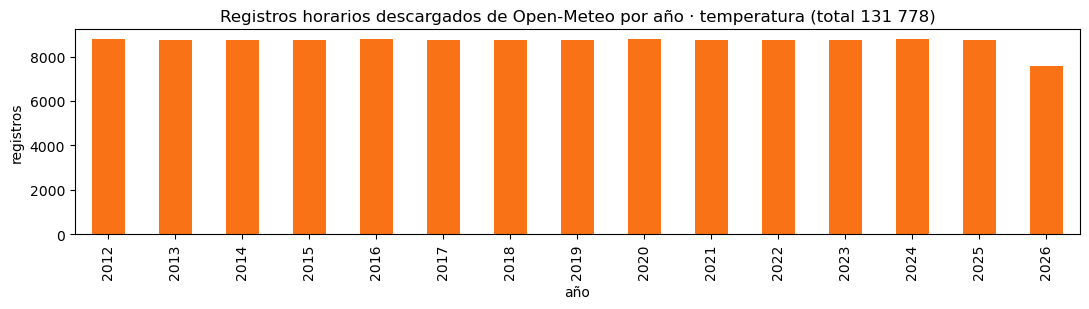

In [5]:
import glob
GOLD_HIST = Path('/home/jovyan/work/Historico_BigData/gold/temperatura')
if not GOLD_HIST.exists():
    raise FileNotFoundError('Falta el histórico: ejecuta antes Historico_BigData/U3_BigData_Historico_OpenMeteo.ipynb')
hist = pd.read_parquet(GOLD_HIST)                     # Parquet Gold particionado por anio/mes (pyarrow)
hist['fecha'] = pd.to_datetime(hist['fecha'])
hist['fecha'] = (hist.fecha.dt.tz_localize('UTC') if hist.fecha.dt.tz is None else hist.fecha).dt.tz_convert('America/Lima')   # hora de Perú
resumen_api = pd.DataFrame([
    {'fuente': 'Forecast API · últimos 60 días (streaming y modelo U2)', 'registros': len(api),
      'desde': api.fecha_evento.min().strftime('%Y-%m-%d'), 'hasta': api.fecha_evento.max().strftime('%Y-%m-%d')},
    {'fuente': 'Historical API ERA5 · histórico 2012–2026 (temperatura a 2 m)', 'registros': len(hist),
      'desde': hist.fecha.min().strftime('%Y-%m-%d'), 'hasta': hist.fecha.max().strftime('%Y-%m-%d')}])
TOTAL_API = int(resumen_api.registros.sum())
print(f'REGISTROS DESCARGADOS DE LA API OPEN-METEO · TEMPERATURA: {TOTAL_API:,}'.replace(',', ' '))
display(resumen_api)

with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
    cur.execute('''CREATE TABLE IF NOT EXISTS api_descargas (dimension TEXT, fuente TEXT, registros BIGINT, desde DATE, hasta DATE,
                   actualizado TIMESTAMPTZ DEFAULT NOW(), PRIMARY KEY (dimension, fuente))''')
    for r in resumen_api.itertuples():
        cur.execute('''INSERT INTO api_descargas (dimension, fuente, registros, desde, hasta) VALUES (%s,%s,%s,%s,%s)
                       ON CONFLICT (dimension, fuente) DO UPDATE SET registros=EXCLUDED.registros, desde=EXCLUDED.desde,
                       hasta=EXCLUDED.hasta, actualizado=NOW()''', ('temperatura', r.fuente, int(r.registros), r.desde, r.hasta))

por_anio = hist.groupby(hist.fecha.dt.year).size()
ax = por_anio.plot(kind='bar', figsize=(11, 3.2), color='#f97316', title=f'Registros horarios descargados de Open-Meteo por año · temperatura (total {TOTAL_API:,})'.replace(',', ' '))
ax.set_xlabel('año'); ax.set_ylabel('registros'); plt.tight_layout(); plt.savefig(RAIZ/'resultados'/'api_descargas_por_anio.png', dpi=120); plt.show()

In [6]:
assert api.temperatura_c.between(-60, 60).all()
print('Huecos distintos de 1 h:', int((api.fecha_evento.diff().dropna() != pd.Timedelta(hours=1)).sum()))
print('Horas bajo 0 °C:', int((api.temperatura_c < 0).sum()), f'({(api.temperatura_c < 0).mean()*100:.1f} %) · cambio horario medio:', round(api.temperatura_c.diff().abs().mean(), 2), '°C')
display(api.temperatura_c.describe().to_frame().T.round(2))

Huecos distintos de 1 h: 0
Horas bajo 0 °C: 34 (2.3 %) · cambio horario medio: 1.39 °C


,count,mean,std,min,25%,50%,75%,max
temperatura_c,1458.0,10.08,5.68,-2.9,5.8,9.5,15.0,21.8


## 7.3 CARGA INICIAL simulada (antes de recibir la API en tiempo real)
90 días horarios que terminan 1 h antes del inicio del histórico API. Se insertan en `eventos_temperatura` con `origen='simulado_carga_inicial'` (idempotente).

In [7]:
from simulador_temperatura import simular
sim = pd.DataFrame(simular(api.fecha_evento.min().to_pydatetime(), dias=90, semilla=7, ubicacion=UBIC)); sim['fecha_evento'] = pd.to_datetime(sim.fecha_evento, utc=True)
sim.to_csv(RAIZ/'datos'/'simulado_carga_inicial_temp.csv', index=False)
assert api.fecha_evento.min() - sim.fecha_evento.max() == pd.Timedelta(hours=1), 'hay hueco entre simulado y API'
filas = [(r.evento_id, r.fecha_evento.isoformat(), r.fecha_evento.isoformat(), r.ubicacion, r.temperatura_c, r.origen, 'carga_inicial') for r in sim.itertuples()]
with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
    execute_values(cur, '''INSERT INTO eventos_temperatura (evento_id,fecha_evento,emitido_utc,ubicacion,temperatura_c,origen,modo_publicacion)
        VALUES %s ON CONFLICT(evento_id) DO NOTHING''', filas, page_size=500)
display(sql("SELECT origen, COUNT(*) filas, MIN(fecha_evento) desde, MAX(fecha_evento) hasta FROM eventos_temperatura GROUP BY origen ORDER BY desde"))

,origen,filas,desde,hasta
0,simulado_carga_inicial,4297,2026-06-19 19:00:00-05:00,2026-09-20 18:00:00-05:00
1,open_meteo_interpolado_2min,1555,2026-11-16 16:10:00-05:00,2026-11-20 12:22:00-05:00
2,open_meteo_modelado,2,2026-11-18 20:00:00-05:00,2026-11-18 21:00:00-05:00


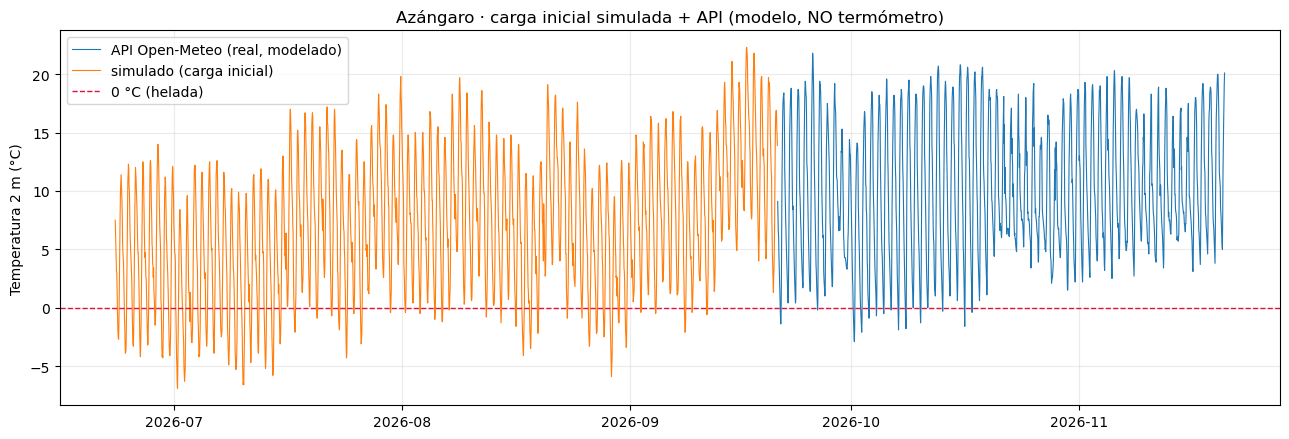

In [8]:
comb = pd.concat([sim.assign(fuente='simulado (carga inicial)'), api.assign(fuente='API Open-Meteo (real, modelado)')]).sort_values('fecha_evento')
fig, ax = plt.subplots(figsize=(13, 4.5))
for f, g in comb.groupby('fuente'): ax.plot(g.fecha_evento, g.temperatura_c, lw=.8, label=f)
ax.axhline(UMBRAL_HELADA, color='crimson', ls='--', lw=1, label='0 °C (helada)'); ax.set_ylabel('Temperatura 2 m (°C)'); ax.legend(); ax.grid(alpha=.25)
ax.set_title('Azángaro · carga inicial simulada + API (modelo, NO termómetro)'); plt.tight_layout(); fig.savefig(RAIZ/'resultados'/'temperatura_api.png', dpi=160, bbox_inches='tight'); plt.show()

## 7.4 Replay y tiempo real hacia Kafka (CMD)
```bat
:: Replay académico: 72 h de la API
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile replay-temperatura run --rm producer-temp-replay
:: Tiempo real: consulta la API cada 10 min y publica cada hora nueva
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile continuo-temperatura up -d producer-temp-continuo
docker compose --env-file .env -f uso-agrosmart/compose.yml logs -f producer-temp-continuo
```
Si no llega un evento nuevo por un rato **no es una caída**: la API entrega una estimación por hora.

### ⏱️ Flujo cada **2 minutos** (humedad de José + temperatura de Mijael)
Open-Meteo solo publica estimaciones **horarias** de modelo (la humedad del suelo no existe a menor resolución) y no hay API pública gratuita con humedad del suelo observada cada 2 min para esta zona. Por eso el productor de 2 min **consulta Open-Meteo (caché de 10 min) y calcula el valor de cada instante por interpolación lineal entre las dos horas que lo rodean**; cada evento va etiquetado `origen='open_meteo_interpolado_2min'`. **No es una medición de sensor.**
```bat
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile tiempo-real-2min up -d producer-humedad-2min producer-temperatura-2min
docker compose --env-file .env -f uso-agrosmart/compose.yml logs -f producer-humedad-2min producer-temperatura-2min
```
Úsalo **en lugar de** `producer-api-continuo` / `producer-temp-continuo` para no mezclar cadencias. En el monitor del Paso 4.2 sube `ESPERA` a 30 s y `N` a 10 para ver crecer los contadores cada 2 min. Los modelos y consumers no cambian: el horizonte (+1/+2/+3 h) se cuenta desde la fecha de cada evento.

---
# SESIÓN 08 · Streaming con Spark (ventanas, watermark, checkpoints)
> **Requisito:** el consumer usa los modelos guardados en la **Sesión 10** (`modelos/`). Si es la primera vez que corres el proyecto, ejecuta antes la sección **10.1** y luego arranca el consumer; después de eso, el orden de este cuaderno (S6 → S11) se sigue tal cual.

El consumer persistente `consumer_streaming_temperatura.py` lanza **3 consultas**:
| Consulta | Qué hace | Checkpoint |
|---|---|---|
| `temp_telemetria` | guarda eventos + **infiere +1 h** | `checkpoints/temp_telemetria` |
| `temp_empresarial` | guarda evaluaciones de riesgo de helada | `checkpoints/temp_empresarial` |
| `temp_ventanas` | ventana 1 h (media/mín/máx), watermark 2 h | `checkpoints/temp_ventanas` |

## 8.1 Arrancar el consumer (CMD, **después** de entrenar)
```bat
docker compose --env-file .env -f pyspark/compose.yml -f pyspark/compose.kafka.yml --profile streaming-temperatura up -d spark-consumer-temperatura
docker compose --env-file .env -f pyspark/compose.yml -f pyspark/compose.kafka.yml logs --tail=80 spark-consumer-temperatura
```
Debe mostrar **3 consultas iniciadas**. Primera vez: descarga el conector de Maven (internet; varios minutos). *RAM:* si tu equipo va justo, detén el consumer de José mientras demuestras el tuyo (`stop spark-consumer`).
## 8.2 Ver llegar los datos en vivo

In [9]:
def estado():
    t = sql('''SELECT (SELECT COUNT(*) FROM eventos_temperatura) AS lecturas,
                      (SELECT COUNT(*) FROM eventos_temperatura WHERE origen='open_meteo_modelado') AS api,
                      (SELECT COUNT(*) FROM eventos_empresariales_temperatura) AS evaluaciones,
                      (SELECT COUNT(*) FROM predicciones_temperatura) AS predicciones,
                      (SELECT COUNT(*) FROM ventanas_temperatura) AS ventanas''')
    t.insert(0, 'hora_utc', datetime.now(timezone.utc).strftime('%H:%M:%S')); return t
N, ESPERA = 6, 10          # 6 lecturas cada 10 s
for i in range(N):
    display(estado().set_index('hora_utc'))
    if i < N-1: time.sleep(ESPERA)

,lecturas,api,evaluaciones,predicciones,ventanas
hora_utc,,,,,
17:22:54,5854,2,1557,1557,62


,lecturas,api,evaluaciones,predicciones,ventanas
hora_utc,,,,,
17:23:04,5854,2,1557,1557,62


,lecturas,api,evaluaciones,predicciones,ventanas
hora_utc,,,,,
17:23:14,5854,2,1557,1557,62


,lecturas,api,evaluaciones,predicciones,ventanas
hora_utc,,,,,
17:23:24,5854,2,1557,1557,62


,lecturas,api,evaluaciones,predicciones,ventanas
hora_utc,,,,,
17:23:34,5854,2,1557,1557,62


,lecturas,api,evaluaciones,predicciones,ventanas
hora_utc,,,,,
17:23:44,5854,2,1557,1557,62


In [10]:
from kafka import KafkaConsumer, TopicPartition
def ultimos(topico, n=5):
    c = KafkaConsumer(bootstrap_servers=KAFKA, enable_auto_commit=False, consumer_timeout_ms=6000, value_deserializer=lambda b: json.loads(b.decode('utf-8')))
    tp = [TopicPartition(topico, p) for p in (c.partitions_for_topic(topico) or [])]
    if not tp: c.close(); return None, {}
    c.assign(tp); fin = c.end_offsets(tp); ini = c.beginning_offsets(tp)
    for t in tp: c.seek(t, max(ini[t], fin[t]-n))
    msgs = [(m.partition, m.offset, m.value) for m in c]; c.close()
    return msgs, {f'{t.topic}[{t.partition}]': (ini[t], fin[t]) for t in tp}
for top in (TOP_TEL, TOP_EMP):
    msgs, offs = ultimos(top, 3); print('=====', top, '| offsets (inicio, fin):', offs)
    for p, o, v in (msgs or []): print(f'  p{p} off={o}', {k: v[k] for k in list(v)[:6]})

===== agrosmart-u2-temperatura-telemetria | offsets (inicio, fin): {'agrosmart-u2-temperatura-telemetria[0]': (0, 1627)}
  p0 off=1624 {'evento_id': '99722cc400bf834643c5596bdcddc0e9', 'fecha_evento': '2026-11-20T12:18:00-05:00', 'ubicacion': 'Azángaro', 'temperatura_c': 20.13, 'origen': 'open_meteo_interpolado_2min', 'modo_publicacion': 'interpolado_2min'}
  p0 off=1625 {'evento_id': 'd6e763ce377db8c809fa179d383b463a', 'fecha_evento': '2026-11-20T12:20:00-05:00', 'ubicacion': 'Azángaro', 'temperatura_c': 20.133, 'origen': 'open_meteo_interpolado_2min', 'modo_publicacion': 'interpolado_2min'}
  p0 off=1626 {'evento_id': 'ac904108cf6440a5eff22b12c2d7e83b', 'fecha_evento': '2026-11-20T12:22:00-05:00', 'ubicacion': 'Azángaro', 'temperatura_c': 20.137, 'origen': 'open_meteo_interpolado_2min', 'modo_publicacion': 'interpolado_2min'}
===== agrosmart-u2-temperatura-empresarial | offsets (inicio, fin): {'agrosmart-u2-temperatura-empresarial[0]': (0, 1627)}
  p0 off=1624 {'evento_id': 'evalT-99

## 8.3 Monitor en tiempo real (Mijael): lo que llega cada 2 minutos
Muestra en el cuaderno lo mismo que la ventana **2 PRODUCTOR TEMPERATURA**: cada evento que llega a Kafka y, al lado, la **predicción +1 h** de Spark y si hay **riesgo de helada** (≤ 0 °C).

In [11]:
# 8.3 · MONITOR EN TIEMPO REAL — lo que llega a Kafka y lo que Spark guarda y predice (igual que la ventana del productor)
import time
from kafka import KafkaConsumer, TopicPartition
MINUTOS = 4   # tiempo de observación: llega un evento nuevo cada 2 minutos
PREVIOS = 5   # últimos mensajes ya publicados, para no empezar con la pantalla vacía

def prediccion_spark(evento_id, espera_s):
    """Busca en PostgreSQL lo que Spark Structured Streaming guardó para ese evento."""
    for _ in range(espera_s):
        with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
            cur.execute("SELECT horizonte_h, ROUND(prediccion_c::numeric, 2) FROM predicciones_temperatura WHERE evento_id = %s ORDER BY horizonte_h", (evento_id,))
            filas = cur.fetchall()
        if filas:
            return filas
        time.sleep(1)
    return []

consumidor = KafkaConsumer(bootstrap_servers=KAFKA, enable_auto_commit=False, consumer_timeout_ms=1000,
                           value_deserializer=lambda b: json.loads(b.decode('utf-8')))
particiones = [TopicPartition(TOP_TEL, p) for p in consumidor.partitions_for_topic(TOP_TEL)]
consumidor.assign(particiones)
for tp, fin in consumidor.end_offsets(particiones).items():
    consumidor.seek(tp, max(0, fin - PREVIOS))

print(f'Escuchando {TOP_TEL} durante {MINUTOS} min · hora de Perú · un evento cada 2 min\n', flush=True)
limite = time.time() + MINUTOS * 60
while time.time() < limite:
    for m in consumidor:
        e = m.value
        nuevo = time.time() - m.timestamp / 1000 < 60          # recién publicado: se espera a que Spark lo procese
        preds = prediccion_spark(e['evento_id'], espera_s=30 if nuevo else 2)
        if preds:
            p1 = float(preds[0][1]); txt = f"+1 h {p1} °C" + ('  ❄ RIESGO DE HELADA' if p1 <= UMBRAL_HELADA else '  sin riesgo de helada')
        else:
            txt = 'aún sin predicción'
        print(f"[TEMPERATURA] fecha={e['fecha_evento']} valor={e['temperatura_c']} °C offset={m.offset}  →  Spark: {txt}", flush=True)
consumidor.close()
print('\nFin del monitoreo. Vuelve a ejecutar la celda para seguir viendo el flujo.')

Escuchando agrosmart-u2-temperatura-telemetria durante 4 min · hora de Perú · un evento cada 2 min

[TEMPERATURA] fecha=2026-11-20T12:14:00-05:00 valor=20.123 °C offset=1622  →  Spark: +1 h 20.35 °C  sin riesgo de helada
[TEMPERATURA] fecha=2026-11-20T12:16:00-05:00 valor=20.127 °C offset=1623  →  Spark: +1 h 20.35 °C  sin riesgo de helada
[TEMPERATURA] fecha=2026-11-20T12:18:00-05:00 valor=20.13 °C offset=1624  →  Spark: +1 h 20.35 °C  sin riesgo de helada
[TEMPERATURA] fecha=2026-11-20T12:20:00-05:00 valor=20.133 °C offset=1625  →  Spark: +1 h 20.35 °C  sin riesgo de helada
[TEMPERATURA] fecha=2026-11-20T12:22:00-05:00 valor=20.137 °C offset=1626  →  Spark: +1 h 20.35 °C  sin riesgo de helada
[TEMPERATURA] fecha=2026-11-20T12:24:00-05:00 valor=20.14 °C offset=1627  →  Spark: +1 h 20.35 °C  sin riesgo de helada
[TEMPERATURA] fecha=2026-11-20T12:26:00-05:00 valor=20.143 °C offset=1628  →  Spark: +1 h 20.35 °C  sin riesgo de helada

Fin del monitoreo. Vuelve a ejecutar la celda para seg

## 8.4 Consultas de verificación

In [12]:
print('Heartbeat de las consultas de temperatura:'); display(sql("SELECT consulta,activa,batch_id,filas_entrada,duracion_ms,retraso_offsets,observado_utc,error FROM metricas_pipeline WHERE consulta LIKE 'temp_%' ORDER BY 1"))
print('Últimas ventanas de 1 h:'); display(sql('SELECT inicio,lecturas,ROUND(temp_media_c::numeric,2) media,temp_min_c minimo,temp_max_c maximo FROM ventanas_temperatura ORDER BY inicio DESC LIMIT 8'))
print('Evaluaciones de riesgo de helada:'); display(sql('SELECT estado, COUNT(*) eventos, ROUND(MIN(temperatura_c)::numeric,1) minima_c FROM eventos_empresariales_temperatura GROUP BY estado ORDER BY 2 DESC'))
print('Últimas lecturas:'); display(sql('SELECT fecha_evento,temperatura_c,origen,modo_publicacion FROM eventos_temperatura ORDER BY fecha_evento DESC LIMIT 6'))

Heartbeat de las consultas de temperatura:


,consulta,activa,batch_id,filas_entrada,duracion_ms,retraso_offsets,observado_utc,error
0,temp_empresarial,True,1601,0,3.0,0.0,2026-11-20 12:27:55.706039-05:00,None
1,temp_telemetria,True,1601,0,3.0,0.0,2026-11-20 12:27:55.706039-05:00,None
2,temp_ventanas,True,1601,0,3.0,0.0,2026-11-20 12:27:55.706039-05:00,None


Últimas ventanas de 1 h:


,inicio,lecturas,media,minimo,maximo
0,2026-11-20 12:00:00-05:00,14,20.12,20.100,20.143
1,2026-11-20 11:00:00-05:00,19,19.73,19.403,20.063
2,2026-11-20 05:00:00-05:00,12,5.38,4.900,5.853
3,2026-11-20 04:00:00-05:00,30,5.06,4.910,5.200
4,2026-11-20 03:00:00-05:00,30,5.51,5.220,5.800
5,2026-11-20 02:00:00-05:00,30,6.05,5.817,6.300
6,2026-11-20 01:00:00-05:00,30,7.02,6.347,7.700
7,2026-11-20 00:00:00-05:00,30,8.17,7.730,8.600


Evaluaciones de riesgo de helada:


,estado,eventos,minima_c
0,normal,1559,3.8


Últimas lecturas:


,fecha_evento,temperatura_c,origen,modo_publicacion
0,2026-11-20 12:26:00-05:00,20.143,open_meteo_interpolado_2min,interpolado_2min
1,2026-11-20 12:24:00-05:00,20.140,open_meteo_interpolado_2min,interpolado_2min
2,2026-11-20 12:22:00-05:00,20.137,open_meteo_interpolado_2min,interpolado_2min
3,2026-11-20 12:20:00-05:00,20.133,open_meteo_interpolado_2min,interpolado_2min
4,2026-11-20 12:18:00-05:00,20.130,open_meteo_interpolado_2min,interpolado_2min
5,2026-11-20 12:16:00-05:00,20.127,open_meteo_interpolado_2min,interpolado_2min


## 8.5 Pruebas de watermark y checkpoint (CMD)
```bat
:: Evento tardío (lectura REAL antigua con ID nuevo, enviada después de que el watermark avanzó)
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile pruebas-temperatura run --rm producer-evento-tardio-temperatura
:: Reinicio sin duplicados
docker compose --env-file .env -f pyspark/compose.yml -f pyspark/compose.kafka.yml stop spark-consumer-temperatura
docker compose --env-file .env -f pyspark/compose.yml -f pyspark/compose.kafka.yml --profile streaming-temperatura up -d spark-consumer-temperatura
```
*No afirmes que el tardío fue descartado sin comprobar su `evento_id` en la base.* Verificación de duplicados:

In [13]:
display(sql('''SELECT 'eventos_temperatura' tabla, COUNT(*) filas, COUNT(DISTINCT evento_id) ids_unicos FROM eventos_temperatura
               UNION ALL SELECT 'predicciones_temperatura', COUNT(*), COUNT(DISTINCT (evento_id||'-'||horizonte_h)) FROM predicciones_temperatura'''))
print('Checkpoints:', sorted(p.name for p in (RAIZ/'checkpoints').iterdir() if p.is_dir()) if (RAIZ/'checkpoints').exists() else 'aún sin crear')

,tabla,filas,ids_unicos
0,eventos_temperatura,5856,5856
1,predicciones_temperatura,1559,1559


Checkpoints: ['temp_empresarial', 'temp_telemetria', 'temp_ventanas']


---
# SESIÓN 09 · Observabilidad y costos
```bat
docker compose --env-file .env -f obs/compose.yml up -d --build
```
Prometheus Targets `http://localhost:9095/targets` · Grafana `http://localhost:3300` · Exportador `http://localhost:9202/metrics` (métricas `agrosmart_temperatura_*`). Alertas nuevas: `AgroSmartTemperaturaConsumerNoActivo` y `AgroSmartTemperaturaHeartbeatAntiguo` (técnicas, no agronómicas).

In [14]:
import requests
PROM = 'http://prometheus:9090'
def prom(q):
    r = requests.get(f'{PROM}/api/v1/query', params={'query': q}, timeout=8); r.raise_for_status(); return r.json()['data']['result']
try:
    for q in ['agrosmart_temperatura_registros', 'agrosmart_temperatura_predicciones', 'agrosmart_temperatura_modelo_rmse', 'agrosmart_consulta_activa{consulta=~"temp_.*"}']:
        print(f'{q:55s}', [(x['metric'].get('consulta') or x['metric'].get('horizonte_h') or '', x['value'][1]) for x in prom(q)])
except Exception as e:
    print('⚠️ Prometheus no responde (¿levantaste obs/compose.yml?):', e)

agrosmart_temperatura_registros                         [('', '5856')]
agrosmart_temperatura_predicciones                      [('', '1559')]
agrosmart_temperatura_modelo_rmse                       [('1', '1.1404861168725797')]
agrosmart_consulta_activa{consulta=~"temp_.*"}          [('temp_telemetria', '1'), ('temp_empresarial', '1'), ('temp_ventanas', '1')]


## 9.1 Costos en soles (supuestos didácticos editables)
Tarifas de laboratorio: **S/ 0.30/h de cómputo** y **S/ 0.40/GB‑mes** (no son precios comerciales). Se estima solo el flujo de temperatura (1 evento/hora por estación).

In [15]:
tam = sql("SELECT pg_total_relation_size('eventos_temperatura') b").b.iloc[0]; n = max(1, int(sql('SELECT COUNT(*) c FROM eventos_temperatura').c.iloc[0]))
bytes_evento = tam / n; TARIFA_H, TARIFA_GB = 0.30, 0.40
esc = []
for nombre, estaciones in (('Actual (1 estación)', 1), ('10 estaciones', 10), ('100 estaciones', 100)):
    eventos_mes = estaciones * 24 * 30; gb = eventos_mes * bytes_evento / 1e9
    computo = 720 * TARIFA_H * (1 if estaciones <= 10 else 2)            # 2 nodos a partir de 100 estaciones (supuesto)
    esc.append(dict(escenario=nombre, eventos_mes=eventos_mes, almacenamiento_gb=round(gb, 4), costo_computo_pen=round(computo, 2), costo_almacen_pen=round(gb*TARIFA_GB, 4), total_pen=round(computo + gb*TARIFA_GB, 2)))
print(f'Tamaño medio por evento (incluye índices): {bytes_evento:.0f} bytes'); display(pd.DataFrame(esc))
print('Complementa con: docker stats --no-stream')

Tamaño medio por evento (incluye índices): 299 bytes


,escenario,eventos_mes,almacenamiento_gb,costo_computo_pen,costo_almacen_pen,total_pen
0,Actual (1 estación),720,0.0002,216.0,0.0001,216.00
1,10 estaciones,7200,0.0022,216.0,0.0009,216.00
2,100 estaciones,72000,0.0216,432.0,0.0086,432.01


Complementa con: docker stats --no-stream


---
# SESIÓN 10 · Series de tiempo: entrenamiento e inferencia
## 10.1 Entrenar el modelo de **+1 hora**
**Se entrena antes del consumer** porque este necesita el modelo guardado.
- **Variables en el instante *t*:** temperatura actual, `hora_seno`, `hora_coseno` (el streaming procesa un evento a la vez, sin lags; ver ablación en la DimensiónU1).
- **Objetivo:** temperatura en *t + 1 h*. **División cronológica 70/15/15** con brecha de 1 fila. Nunca se baraja.
- **4 algoritmos MLlib** (Lineal, Random Forest, Árbol, GBT) **contra la persistencia** («igual que ahora»). Se elige por **validación**; la **prueba (API real)** mide generalización.

In [16]:
base = pd.concat([sim, api]).drop_duplicates('fecha_evento').sort_values('fecha_evento').reset_index(drop=True)
base['hora'] = base.fecha_evento.dt.hour; base['hora_seno'] = np.sin(2*np.pi*base.hora/24); base['hora_coseno'] = np.cos(2*np.pi*base.hora/24)
vars_ml = ['temperatura_c', 'hora_seno', 'hora_coseno']
print(f'Base: {len(base):,} h (simulado {len(sim):,} + API {len(api):,}) · huecos:', int((base.fecha_evento.diff().dropna() != pd.Timedelta(hours=1)).sum()))
rm, ma, r2 = [RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName=m) for m in ('rmse', 'mae', 'r2')]
modelos, metricas, comps = {}, [], []
for h in (1,):
    d = base.copy(); d['fecha_objetivo'] = d.fecha_evento.shift(-h); d['label'] = d.temperatura_c.shift(-h)
    d = d.loc[(d.fecha_objetivo - d.fecha_evento).dt.total_seconds() == h*3600].dropna(subset=vars_ml + ['label']).reset_index(drop=True)
    a_, b_ = int(len(d)*.7), int(len(d)*.85)
    train = spark.createDataFrame(d.iloc[:a_-h][vars_ml+['label']].astype(float)); val = spark.createDataFrame(d.iloc[a_:b_-h][vars_ml+['label']].astype(float))
    test = spark.createDataFrame(d.iloc[b_:][vars_ml+['label']].astype(float))
    base_rmse = rm.evaluate(test.withColumn('prediction', F.col('temperatura_c')))
    cand = {'RegresionLineal': LinearRegression(featuresCol='features', labelCol='label', maxIter=60),
            'RandomForest': RandomForestRegressor(featuresCol='features', labelCol='label', numTrees=40, maxDepth=6, seed=42),
            'ArbolDecision': DecisionTreeRegressor(featuresCol='features', labelCol='label', maxDepth=6, seed=42),
            'GradientBoostedTrees': GBTRegressor(featuresCol='features', labelCol='label', maxIter=20, maxDepth=4, seed=42)}
    aj = {n: None for n in cand}
    for n, est in cand.items():
        m = Pipeline(stages=[VectorAssembler(inputCols=vars_ml, outputCol='features'), est]).fit(train); aj[n] = (rm.evaluate(m.transform(val)), m)
    ganador = min(aj, key=lambda n: aj[n][0]); mg = aj[ganador][1]
    for n, (rv, m) in aj.items():
        pt = m.transform(test); comps.append(dict(horizonte_h=h, modelo=n, rmse_validacion=rv, rmse_prueba=rm.evaluate(pt), mae_prueba=ma.evaluate(pt), r2_prueba=r2.evaluate(pt), seleccionado=(n == ganador)))
    sel = mg.transform(test)
    metricas.append(dict(horizonte_h=h, modelo=ganador, rmse=rm.evaluate(sel), mae=ma.evaluate(sel), r2=r2.evaluate(sel), rmse_validacion=aj[ganador][0],
                         baseline_rmse=base_rmse, n_train=train.count(), n_validacion=val.count(), n_prueba=test.count()))
    mg.write().overwrite().save(str(RAIZ/'modelos'/f'temperatura_{h}h'))
    print(f'+{h} h | elegido: {ganador} | RMSE prueba {metricas[-1]["rmse"]:.3f} °C | persistencia {base_rmse:.3f} °C')
met_df, comp_df = pd.DataFrame(metricas), pd.DataFrame(comps)
met_df.to_csv(RAIZ/'resultados'/'metricas_modelo_temperatura.csv', index=False); comp_df.to_csv(RAIZ/'resultados'/'comparacion_cuatro_modelos_temperatura.csv', index=False)
print('MODELO ELEGIDO:'); display(met_df.round(4)); print('CANDIDATOS (4):'); display(comp_df.round(4))

Base: 3,618 h (simulado 2,160 + API 1,458) · huecos: 0
+1 h | elegido: ArbolDecision | RMSE prueba 1.183 °C | persistencia 1.643 °C
MODELO ELEGIDO:


,horizonte_h,modelo,rmse,mae,r2,rmse_validacion,baseline_rmse,n_train,n_validacion,n_prueba
0,1,ArbolDecision,1.1834,0.8316,0.9426,1.3301,1.6429,2530,542,543


CANDIDATOS (4):


,horizonte_h,modelo,rmse_validacion,rmse_prueba,mae_prueba,r2_prueba,seleccionado
0,1,RegresionLineal,1.3474,1.2234,0.9058,0.9386,False
1,1,RandomForest,1.7112,1.7066,1.3854,0.8805,False
2,1,ArbolDecision,1.3301,1.1834,0.8316,0.9426,True
3,1,GradientBoostedTrees,1.3489,1.2961,0.8964,0.9311,False


### Cómo leer el resultado
- RMSE/MAE en **grados Celsius**. Si el modelo no supera a la persistencia, **se informa tal cual**. Con la **hora** como variable, un modelo suele ganar a la persistencia porque la temperatura tiene un ciclo diario fuerte.
- La **prueba es 100 % API real** (último 15 %).

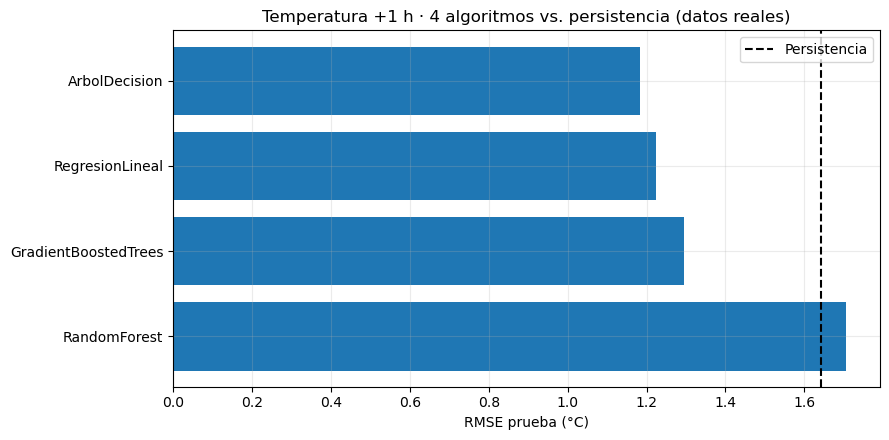

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
c = comp_df.sort_values('rmse_prueba'); ax.barh(c.modelo[::-1], c.rmse_prueba[::-1]); ax.axvline(met_df.baseline_rmse.iloc[0], color='k', ls='--', label='Persistencia')
ax.set_xlabel('RMSE prueba (°C)'); ax.set_title('Temperatura +1 h · 4 algoritmos vs. persistencia (datos reales)'); ax.legend(); ax.grid(alpha=.25); plt.tight_layout()
fig.savefig(RAIZ/'resultados'/'comparacion_modelos_temperatura.png', dpi=170, bbox_inches='tight'); plt.show()

## 10.2 Guardar métricas en PostgreSQL (las muestra Grafana)

In [18]:
with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
    for m in metricas:
        cur.execute('''INSERT INTO metricas_modelo_temperatura (horizonte_h,modelo,rmse,mae,r2,rmse_validacion,baseline_rmse,n_train,n_validacion,n_prueba) VALUES (%s,%s,%s,%s,%s,%s,%s,%s,%s,%s)
          ON CONFLICT(horizonte_h) DO UPDATE SET modelo=EXCLUDED.modelo,rmse=EXCLUDED.rmse,mae=EXCLUDED.mae,r2=EXCLUDED.r2,rmse_validacion=EXCLUDED.rmse_validacion,
          baseline_rmse=EXCLUDED.baseline_rmse,n_train=EXCLUDED.n_train,n_validacion=EXCLUDED.n_validacion,n_prueba=EXCLUDED.n_prueba,fecha_registro=NOW()''',
          tuple(m[k] for k in ['horizonte_h','modelo','rmse','mae','r2','rmse_validacion','baseline_rmse','n_train','n_validacion','n_prueba']))
    for m in comps:
        cur.execute('''INSERT INTO comparacion_modelos_temperatura (horizonte_h,modelo,rmse_validacion,rmse_prueba,mae_prueba,r2_prueba,seleccionado) VALUES (%s,%s,%s,%s,%s,%s,%s)
          ON CONFLICT(horizonte_h,modelo) DO UPDATE SET rmse_validacion=EXCLUDED.rmse_validacion,rmse_prueba=EXCLUDED.rmse_prueba,mae_prueba=EXCLUDED.mae_prueba,
          r2_prueba=EXCLUDED.r2_prueba,seleccionado=EXCLUDED.seleccionado,fecha_registro=NOW()''', tuple(m[k] for k in ['horizonte_h','modelo','rmse_validacion','rmse_prueba','mae_prueba','r2_prueba','seleccionado']))
print('Modelos en disco:', sorted(p.name for p in (RAIZ/'modelos').iterdir() if p.name.startswith('temperatura_')))
display(sql('SELECT * FROM metricas_modelo_temperatura'))

Modelos en disco: ['temperatura_1h']


,horizonte_h,modelo,rmse,mae,r2,rmse_validacion,baseline_rmse,n_train,n_validacion,n_prueba,fecha_registro
0,1,ArbolDecision,1.183424,0.831631,0.942551,1.330133,1.642921,2530,542,543,2026-11-20 12:28:27.167114-05:00


---
## 10.3 Inferencia: temperatura esperada **una hora después**
El consumer predice **cada evento que llega**. Aquí además se hace un **pronóstico «ahora»** con la última lectura y el **modelo guardado** (el mismo `PipelineModel` que usa el streaming). `es_retro=TRUE` → el objetivo ya ocurrió (replay); `FALSE` → predicción prospectiva. No los mezcles al evaluar.

In [19]:
ult = sql('''SELECT evento_id,fecha_evento,temperatura_c,origen FROM eventos_temperatura WHERE fecha_evento <= NOW() ORDER BY fecha_evento DESC LIMIT 1''').iloc[0]
f0 = pd.Timestamp(ult.fecha_evento).tz_convert('UTC'); print('Última lectura:', f0, '|', ult.temperatura_c, '°C | origen', ult.origen)
sdf = spark.createDataFrame(pd.DataFrame([{'temperatura_c': float(ult.temperatura_c), 'hora_seno': math.sin(2*math.pi*f0.hour/24), 'hora_coseno': math.cos(2*math.pi*f0.hour/24)}]))
m1 = PipelineModel.load(str(RAIZ/'modelos'/'temperatura_1h')); pred = float(m1.transform(sdf).select('prediction').collect()[0][0])
obj = f0 + pd.Timedelta(hours=1); retro = bool(pd.Timestamp.now(tz='UTC') >= obj)
alerta = 'ALERTA DE HELADA (≤ 0 °C)' if pred <= UMBRAL_HELADA else ('vigilancia (0–3 °C)' if pred <= UMBRAL_HELADA + 3 else 'normal')
print(f'Predicción para {obj}: {pred:.2f} °C (persistencia: {float(ult.temperatura_c):.1f} °C) → estado simulado: {alerta} · es_retro={retro}')
with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
    cur.execute('''INSERT INTO predicciones_temperatura (evento_id,horizonte_h,fecha_evento,fecha_objetivo,prediccion_c,modelo,es_retro) VALUES (%s,1,%s,%s,%s,%s,%s)
                   ON CONFLICT(evento_id,horizonte_h) DO NOTHING''', (ult.evento_id, f0.to_pydatetime(), obj.to_pydatetime(), pred, m1.stages[-1].__class__.__name__, retro))

Última lectura: 2026-11-20 17:28:00+00:00 | 20.147 °C | origen open_meteo_interpolado_2min
Predicción para 2026-11-20 18:28:00+00:00: 20.35 °C (persistencia: 20.1 °C) → estado simulado: normal · es_retro=False


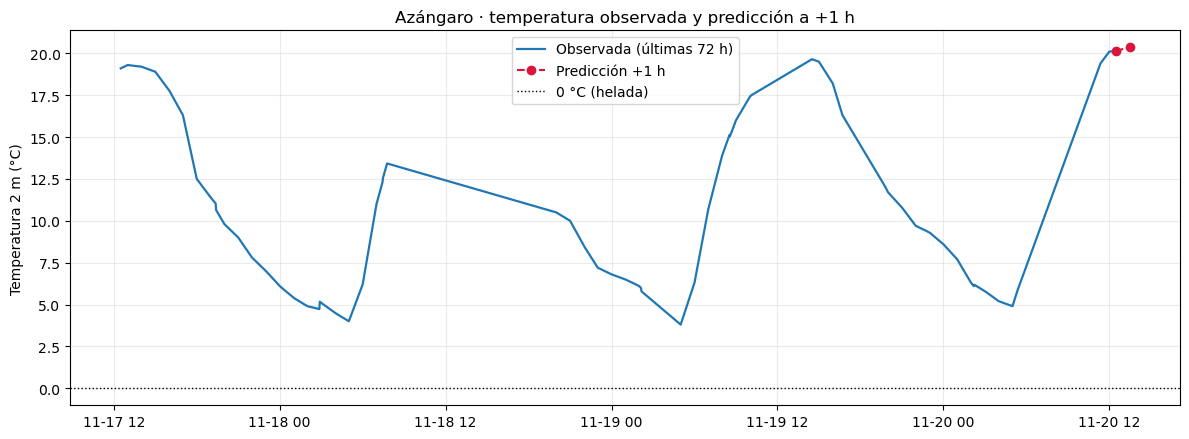

In [20]:
hist = sql("SELECT fecha_evento, temperatura_c FROM eventos_temperatura WHERE fecha_evento <= NOW() AND fecha_evento >= NOW() - INTERVAL '72 hours' ORDER BY 1")
fig, ax = plt.subplots(figsize=(12, 4.5)); ax.plot(hist.fecha_evento, hist.temperatura_c, lw=1.6, label='Observada (últimas 72 h)')
ax.plot([f0, obj], [float(ult.temperatura_c), pred], 'o--', color='crimson', label='Predicción +1 h'); ax.axhline(UMBRAL_HELADA, color='k', ls=':', lw=1, label='0 °C (helada)')
ax.set_ylabel('Temperatura 2 m (°C)'); ax.grid(alpha=.25); ax.legend(); ax.set_title('Azángaro · temperatura observada y predicción a +1 h'); plt.tight_layout()
fig.savefig(RAIZ/'resultados'/'pronostico_1h.png', dpi=170, bbox_inches='tight'); plt.show()

## 10.4 Error real de las predicciones cuyo objetivo ya ocurrió (solo datos de la API)

In [21]:
display(sql('''SELECT es_retro, COUNT(*) predicciones FROM predicciones_temperatura GROUP BY es_retro'''))
ev = sql('''SELECT p.prediccion_c, t.temperatura_c AS observada, e.temperatura_c AS actual FROM predicciones_temperatura p
            JOIN eventos_temperatura t ON t.fecha_evento = p.fecha_objetivo JOIN eventos_temperatura e ON e.evento_id = p.evento_id
            WHERE t.origen = 'open_meteo_modelado' ''')
if len(ev):
    rm_m = float(np.sqrt(((ev.prediccion_c - ev.observada)**2).mean())); rm_p = float(np.sqrt(((ev.actual - ev.observada)**2).mean()))
    print(f'n={len(ev)} · RMSE modelo {rm_m:.3f} °C vs. persistencia {rm_p:.3f} °C → {"el modelo supera" if rm_m < rm_p else "NO supera"} a la persistencia en este tramo')
else: print('Aún no hay objetivos cumplidos con datos de la API; espera nuevas horas.')

,es_retro,predicciones
0,False,841
1,True,719


n=1 · RMSE modelo 0.439 °C vs. persistencia 0.500 °C → el modelo supera a la persistencia en este tramo


---
# SESIÓN 11 · BI/ML en el **Grafana común** del equipo
El tablero `AgroSmart Puno U2 | Humedad (José) + Temperatura (Mijael) — BI/ML v3` (uid `agrosmart-puno-humedad-u2-v2`) ya está aprovisionado en `obs/grafana/dashboards/agrosmart_u2.json`: los paneles de José ocupan las filas 01–06 y **los de Mijael la fila 07 (temperatura)**. Todo en **un solo tablero**, no en instancias separadas.

**Pasos (http://localhost:3300):** iniciar sesión → *Dashboards → AgroSmart U2* → bajar a **«07 · MIJAEL · TEMPERATURA»** → rango **Last 180 days** (carga inicial + API) o *Last 7 days* para el seguimiento reciente. Si no aparece: *Dashboards → New → Import* y subir el JSON.
Paneles: KPI de última temperatura, última predicción +1 h, **alerta de helada** (horas ≤ 0 °C en 24 h), temperatura observada vs. predicción +1 h, ventanas de 1 h (mín/media/máx), evaluaciones de riesgo y comparación de los 4 algoritmos. Captura **un solo screenshot** con reloj del sistema.

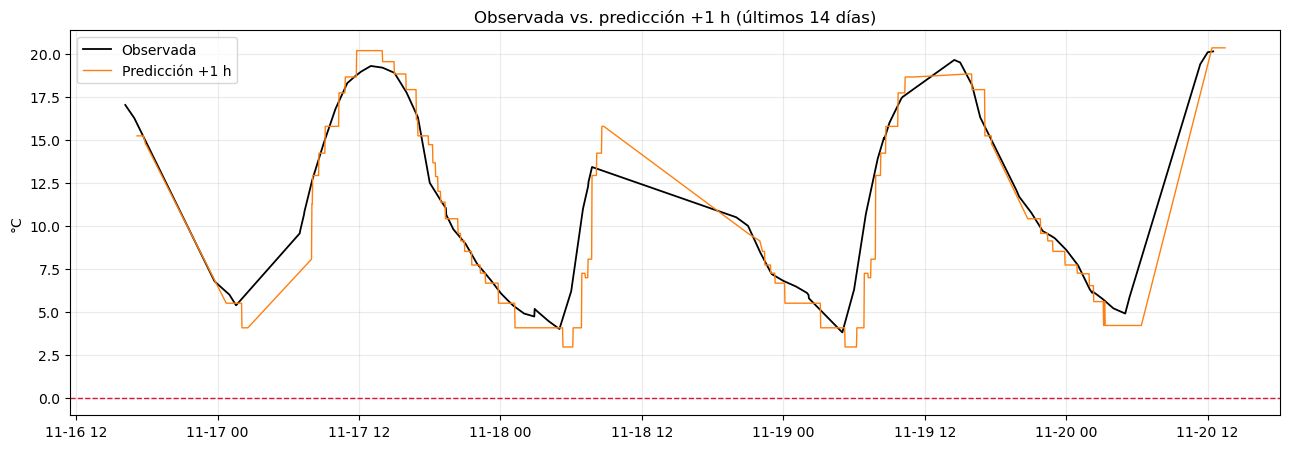

Exportado: 1560 filas


In [22]:
obs_df = sql("SELECT fecha_evento, temperatura_c FROM eventos_temperatura WHERE fecha_evento BETWEEN NOW() - INTERVAL '14 days' AND NOW() ORDER BY 1")
pr = sql("SELECT fecha_objetivo, prediccion_c FROM predicciones_temperatura WHERE horizonte_h=1 AND fecha_objetivo >= NOW() - INTERVAL '14 days' ORDER BY 1")
fig, ax = plt.subplots(figsize=(13, 4.6)); ax.plot(obs_df.fecha_evento, obs_df.temperatura_c, color='k', lw=1.3, label='Observada')
if len(pr): ax.plot(pr.fecha_objetivo, pr.prediccion_c, color='tab:orange', lw=1, label='Predicción +1 h')
ax.axhline(UMBRAL_HELADA, color='crimson', ls='--', lw=1); ax.set_ylabel('°C'); ax.grid(alpha=.25); ax.legend(); ax.set_title('Observada vs. predicción +1 h (últimos 14 días)'); plt.tight_layout(); plt.show()
exp = sql('''SELECT p.fecha_evento, p.fecha_objetivo, p.prediccion_c, t.temperatura_c observada, p.es_retro, p.modelo FROM predicciones_temperatura p
             LEFT JOIN eventos_temperatura t ON t.fecha_evento = p.fecha_objetivo ORDER BY p.fecha_objetivo DESC''')
exp.to_csv(RAIZ/'resultados'/'predicciones_temperatura_export.csv', index=False); print('Exportado:', len(exp), 'filas')

---
# SESIÓN 12 · Evidencias y ficha U2
## 12.1 Evidencia automática

In [23]:
ev = {'generado_utc': datetime.now(timezone.utc).isoformat(), 'integrante': 'Mijael Yurins Coaquira Justo', 'dimension': 'Temperatura exterior (Azángaro) +1 h',
  'conteos': sql('''SELECT (SELECT COUNT(*) FROM eventos_temperatura) lecturas, (SELECT COUNT(*) FROM eventos_temperatura WHERE origen='simulado_carga_inicial') simulado_carga_inicial,
      (SELECT COUNT(*) FROM eventos_temperatura WHERE origen='open_meteo_modelado') api_open_meteo, (SELECT COUNT(*) FROM eventos_empresariales_temperatura) evaluaciones,
      (SELECT COUNT(*) FROM predicciones_temperatura) predicciones, (SELECT COUNT(*) FROM ventanas_temperatura) ventanas''').iloc[0].astype(int).to_dict(),
  'modelo': sql('SELECT horizonte_h,modelo,rmse,mae,r2,baseline_rmse,n_train,n_validacion,n_prueba FROM metricas_modelo_temperatura').round(5).to_dict('records'),
  'offsets_kafka': {t: ultimos(t, 1)[1] for t in (TOP_TEL, TOP_EMP)},
  'consultas_spark': sql("SELECT consulta,activa,batch_id,observado_utc::text AS observado_utc,error FROM metricas_pipeline WHERE consulta LIKE 'temp_%' ORDER BY 1").to_dict('records')}
(RAIZ/'evidencias'/'evidencia_u2_temperatura.json').write_text(json.dumps(ev, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
print(json.dumps(ev['conteos'], indent=2)); print('Guardado en', RAIZ/'evidencias'/'evidencia_u2_temperatura.json')

{
  "lecturas": 5857,
  "simulado_carga_inicial": 4297,
  "api_open_meteo": 2,
  "evaluaciones": 1560,
  "predicciones": 1560,
  "ventanas": 62
}
Guardado en /home/jovyan/work/Sensortemperatura/evidencias/evidencia_u2_temperatura.json
